# Ridge Regression

 1. Feature Engineering
2. Prepare Training and Validation Data
3. Model Training and Evaluation
4. Visualize Model Predictions
5. Peak Demand Analysis

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
from src.build_features import build_features

features = build_features()

In [3]:
features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 34589 entries, 2006-12-16 17:00:00 to 2010-11-26 21:00:00
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   target_kw        34085 non-null  float64
 1   hour             34589 non-null  int32  
 2   day_of_week      34589 non-null  int32  
 3   month            34589 non-null  int32  
 4   is_weekend       34589 non-null  int64  
 5   lag_24           34062 non-null  float64
 6   lag_168          33918 non-null  float64
 7   lag_1            34085 non-null  float64
 8   rolling_mean_24  32494 non-null  float64
dtypes: float64(5), int32(3), int64(1)
memory usage: 2.2 MB


In [4]:
features.tail(10)

,target_kw,hour,day_of_week,month,is_weekend,lag_24,lag_168,lag_1,rolling_mean_24
timestamp,,,,,,,,,
2010-11-26 12:00:00,1.490200,12,4,11,0,0.499733,1.390700,1.338900,1.150549
2010-11-26 13:00:00,1.612933,13,4,11,0,0.356233,1.594400,1.490200,1.083682
2010-11-26 14:00:00,1.407767,14,4,11,0,0.300667,1.521100,1.612933,1.012136
2010-11-26 15:00:00,0.876433,15,4,11,0,0.333000,1.622867,1.407767,0.963426
2010-11-26 16:00:00,1.067933,16,4,11,0,0.541800,1.469700,0.876433,0.949582
2010-11-26 17:00:00,1.725900,17,4,11,0,1.480100,0.824267,1.067933,0.930464
2010-11-26 18:00:00,1.573467,18,4,11,0,2.211600,1.018467,1.725900,0.936733
2010-11-26 19:00:00,1.659333,19,4,11,0,2.330467,1.249767,1.573467,0.971410
2010-11-26 20:00:00,1.163700,20,4,11,0,1.647833,1.665267,1.659333,0.943700


## Prepare Training and Validation Data

Remove rows with missing targets or features while preserving
chronological order.

In [5]:
model_df = features.dropna().copy()

train_df = model_df.loc[: "2008-12-31 23:00"]
val_df = model_df.loc["2009-01-01":"2009-12-31 23:00"]
test_df = model_df.loc["2010-01-01":]

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 16626
Validation: 8124
Test: 6861


## Separate features from targets

In [25]:
X_train = train_df.drop(columns=["target_kw"])
y_train = train_df["target_kw"]

X_val = val_df.drop(columns=["target_kw"])
y_val = val_df["target_kw"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_train shape: (16626, 8)
y_train shape: (16626,)
X_val shape: (8124, 8)
y_val shape: (8124,)


In [31]:
def encode_calendar(X):
    X = X.copy()

    for col, period in [
        ("hour", 24),
        ("day_of_week", 7),
        ("month", 12),
    ]:
        angle = 2 * np.pi * X[col] / period

        X[f"{col}_sin"] = np.sin(angle)
        X[f"{col}_cos"] = np.cos(angle)

    # Weekday/weekend interaction features
    X["hour_sin_weekend"] = (
        X["hour_sin"] * X["is_weekend"]
    )

    X["hour_cos_weekend"] = (
        X["hour_cos"] * X["is_weekend"]
    )

    return X.drop(
        columns=["hour", "day_of_week", "month"]
    )

X_train_encoded = encode_calendar(X_train)
X_val_encoded = encode_calendar(X_val)

X_train_encoded.head()

,is_weekend,lag_24,lag_168,lag_1,rolling_mean_24,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos,hour_sin_weekend,hour_cos_weekend
timestamp,,,,,,,,,,,,,
2006-12-23 18:00:00,1,2.686967,3.632200,5.452533,1.153442,-1.000000,-1.836970e-16,-0.974928,-0.222521,-2.449294e-16,1.0,-1.000000,-1.836970e-16
2006-12-23 19:00:00,1,3.938167,3.400233,3.879400,1.225985,-0.965926,2.588190e-01,-0.974928,-0.222521,-2.449294e-16,1.0,-0.965926,2.588190e-01
2006-12-23 20:00:00,1,3.536067,3.268567,4.117833,1.271764,-0.866025,5.000000e-01,-0.974928,-0.222521,-2.449294e-16,1.0,-0.866025,5.000000e-01
2006-12-23 21:00:00,1,4.548667,3.056467,4.181400,1.420364,-0.707107,7.071068e-01,-0.974928,-0.222521,-2.449294e-16,1.0,-0.707107,7.071068e-01
2006-12-23 22:00:00,1,3.065067,2.200133,3.288433,1.536397,-0.500000,8.660254e-01,-0.974928,-0.222521,-2.449294e-16,1.0,-0.500000,8.660254e-01


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge_pipeline.fit(X_train_encoded, y_train)

print("Ridge Regression trained successfully!")

Ridge Regression trained successfully!


/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [33]:
ridge_predictions = ridge_pipeline.predict(
    X_val_encoded
)

print("First 5 predictions:")
print(ridge_predictions[:5])

print("\nFirst 5 actual values:")
print(y_val.iloc[:5].values)

First 5 predictions:
[0.79418953 0.63760422 0.56903708 0.59459142 0.65683741]

First 5 actual values:
[0.53493333 0.54046667 0.57536667 0.5265     0.5219    ]


/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


## Model Evaluation

Evaluate Ridge Regression against daily and weekly
seasonal-naive baselines using MAE and RMSE on
identical validation timestamps.

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a comparison dataset
comparison = val_df[
    ["target_kw", "lag_1", "lag_24", "lag_168"]
].copy()

comparison["ridge"] = ridge_predictions

# Evaluate all three forecasting approaches
results = []

for model, column in [
    ("Hourly Naive", "lag_1"),
    ("Daily Naive", "lag_24"),
    ("Weekly Naive", "lag_168"),
    ("Ridge Regression", "ridge")
]:
    mae = mean_absolute_error(
        comparison["target_kw"],
        comparison[column]
    )

    rmse = np.sqrt(
        mean_squared_error(
            comparison["target_kw"],
            comparison[column]
        )
    )

    results.append({
        "Model": model,
        "MAE (kW)": mae,
        "RMSE (kW)": rmse
    })

results_df = pd.DataFrame(results)
results_df.sort_values("MAE (kW)")

,Model,MAE (kW),RMSE (kW)
3,Ridge Regression,0.395167,0.563180
0,Hourly Naive,0.431716,0.658933
2,Weekly Naive,0.565109,0.840827
1,Daily Naive,0.609805,0.899521


In [35]:
print("Minimum Ridge prediction:", ridge_predictions.min())
print("Maximum Ridge prediction:", ridge_predictions.max())
print("Negative predictions:", (ridge_predictions < 0).sum())

print("\nActual validation range:")
print("Minimum:", y_val.min())
print("Maximum:", y_val.max())

Minimum Ridge prediction: 0.1866154852337678
Maximum Ridge prediction: 4.683108803917785
Negative predictions: 0

Actual validation range:
Minimum: 0.17973333333333336
Maximum: 5.2338000000000005


## Visualize Model Predictions

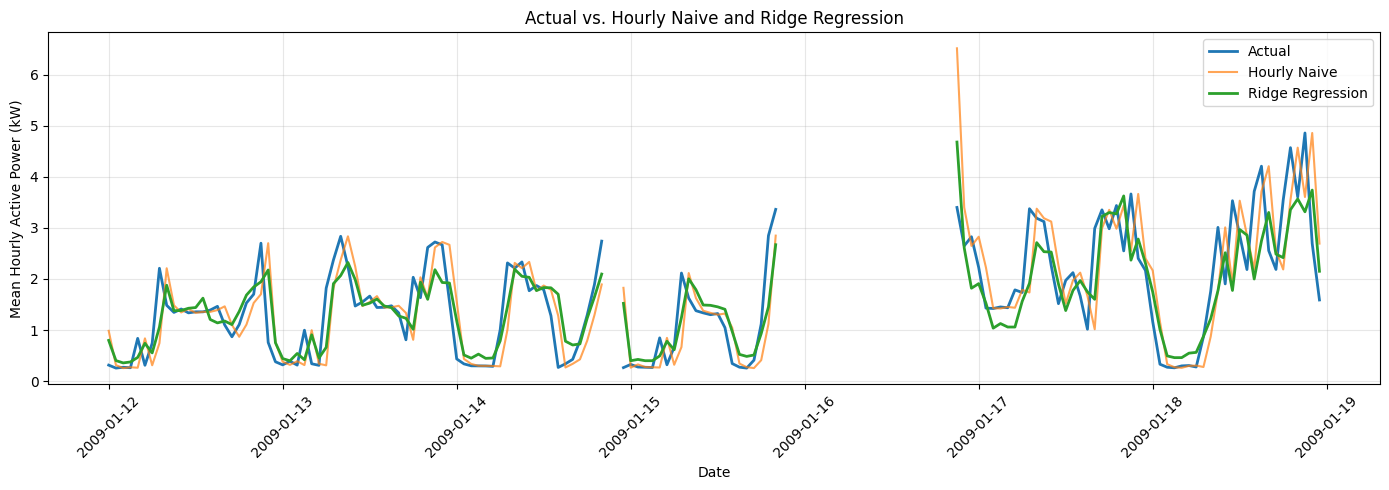

In [36]:
sample = comparison.loc["2009-01-12":"2009-01-18"]

sample = sample.asfreq("h")

plt.figure(figsize=(14, 5))

plt.plot(sample.index, sample["target_kw"], label="Actual", linewidth=2)

plt.plot(sample.index, sample["lag_1"], label="Hourly Naive", alpha=0.7)

plt.plot(sample.index, sample["ridge"], label="Ridge Regression", linewidth=2)

plt.title("Actual vs. Hourly Naive and Ridge Regression")
plt.xlabel("Date")
plt.ylabel("Mean Hourly Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
ridge_error = (
    comparison["target_kw"] - comparison["ridge"]
).abs()

hourly_error = (
    comparison["target_kw"] - comparison["lag_1"]
).abs()

ridge_win_rate = (ridge_error < hourly_error).mean()

print(f"Ridge win rate: {ridge_win_rate:.2%}")

Ridge win rate: 51.88%


## 5. Peak Demand Analysis

Investigate how Ridge Regression performs during the
highest electricity demand observations in validation.

In [38]:
peak_comparison = comparison.nlargest(10, "target_kw").copy()

peak_comparison["ridge_error"] = (peak_comparison["target_kw"] - peak_comparison["ridge"])

peak_comparison["hourly_error"] = (peak_comparison["target_kw"] - peak_comparison["lag_1"])

peak_comparison

,target_kw,lag_1,lag_24,lag_168,ridge,ridge_error,hourly_error
timestamp,,,,,,,
2009-02-11 18:00:00,5.233800,1.013400,1.303867,2.542400,1.313640,3.920160,4.220400
2009-04-12 21:00:00,5.133967,5.098300,2.738933,1.259500,3.726315,1.407652,0.035667
2009-11-22 20:00:00,5.115167,3.818933,3.538233,2.040500,3.263638,1.851529,1.296233
2009-04-12 20:00:00,5.098300,2.653167,4.145133,2.183467,2.631815,2.466485,2.445133
2009-01-24 11:00:00,5.073400,1.861733,1.592900,1.516567,1.869931,3.203469,3.211667
2009-01-31 17:00:00,5.072500,3.407433,3.019767,1.065167,2.951836,2.120664,1.665067
2009-01-18 21:00:00,4.860700,3.606900,3.665800,3.503933,3.316283,1.544417,1.253800
2009-11-03 20:00:00,4.830833,4.125833,2.753667,2.055633,3.251326,1.579507,0.705000
2009-02-22 17:00:00,4.829433,3.718800,0.506933,0.357133,2.667260,2.162174,1.110633


## Forecasting Error by Hour of Day

Compare Ridge Regression against hourly, daily, and
weekly naive baselines to identify when the model
improves forecasting accuracy.

In [46]:
hourly_errors = comparison.copy()

hourly_errors["hour"] = hourly_errors.index.hour

hourly_errors["ridge_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["ridge"]
).abs()

hourly_errors["hourly_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_1"]
).abs()

hourly_errors["daily_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_24"]
).abs()

hourly_errors["weekly_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_168"]
).abs()

In [40]:
error_by_hour = hourly_errors.groupby("hour")[
    [
        "ridge_error",
        "hourly_error",
        "daily_error",
        "weekly_error"
    ]
].mean()

error_by_hour

,ridge_error,hourly_error,daily_error,weekly_error
hour,,,,
0,0.284230,0.341994,0.418389,0.348756
1,0.188907,0.178609,0.312050,0.297032
2,0.155357,0.138851,0.245778,0.233540
3,0.149204,0.123845,0.217616,0.224962
4,0.181839,0.164672,0.230513,0.250612
5,0.199835,0.186459,0.240556,0.251770
6,0.342547,0.439315,0.423781,0.409757
7,0.676452,0.830938,0.710324,0.591540
8,0.377105,0.490877,0.577303,0.555871


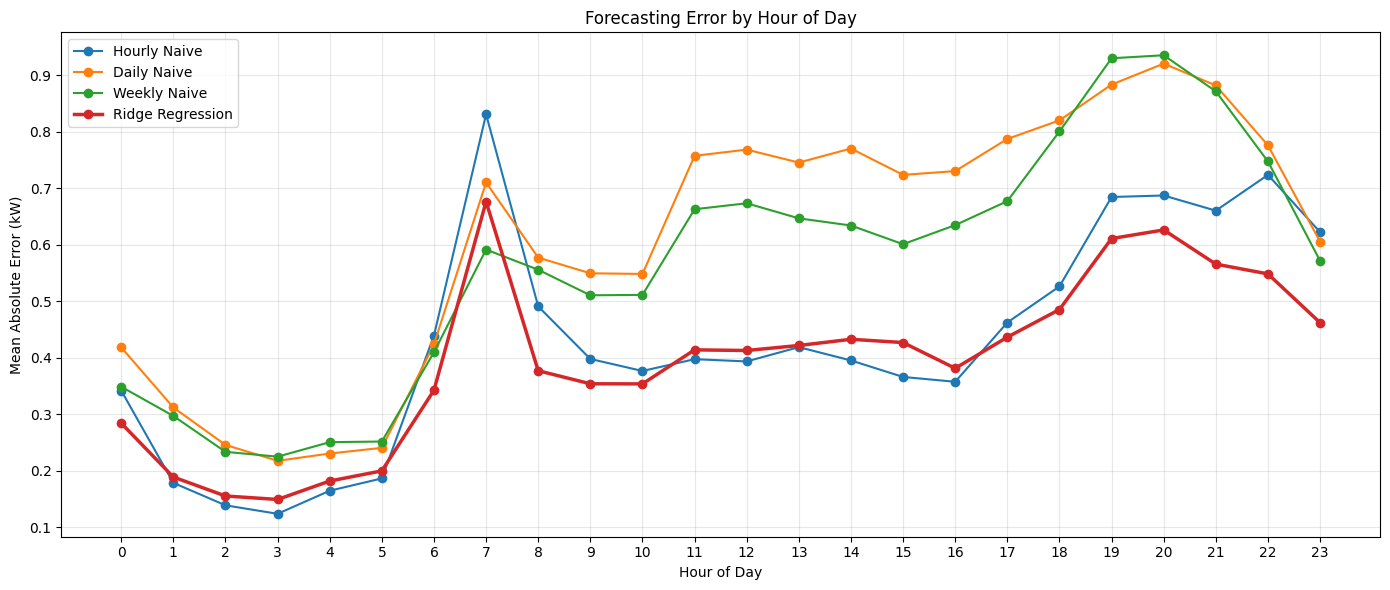

In [41]:
plt.figure(figsize=(14, 6))

plt.plot(
    error_by_hour.index,
    error_by_hour["hourly_error"],
    marker="o",
    label="Hourly Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["daily_error"],
    marker="o",
    label="Daily Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["weekly_error"],
    marker="o",
    label="Weekly Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["ridge_error"],
    marker="o",
    linewidth=2.5,
    label="Ridge Regression"
)

plt.title("Forecasting Error by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Forecasting Error by Weekday vs. Weekend

Compare Ridge Regression against the three naive
baselines across weekday and weekend hours.

Investigate whether Ridge improves forecasting during
the weekday morning demand peak, particularly at 7 AM.

In [42]:
weekday_errors = hourly_errors.copy()

weekday_errors["day_of_week"] = (
    weekday_errors.index.dayofweek
)

weekday_errors["is_weekend"] = (
    weekday_errors["day_of_week"] >= 5
)

weekday_errors.head()

,target_kw,lag_1,lag_24,lag_168,ridge,hour,ridge_error,hourly_error,daily_error,weekly_error,day_of_week,is_weekend
timestamp,,,,,,,,,,,,
2009-01-01 00:00:00,0.534933,0.575433,0.267567,1.842567,0.794190,0,0.259256,0.040500,0.267367,1.307633,3,False
2009-01-01 01:00:00,0.540467,0.534933,0.250600,0.873767,0.637604,1,0.097138,0.005533,0.289867,0.333300,3,False
2009-01-01 02:00:00,0.575367,0.540467,0.290900,0.267833,0.569037,2,0.006330,0.034900,0.284467,0.307533,3,False
2009-01-01 03:00:00,0.526500,0.575367,0.263967,0.271167,0.594591,3,0.068091,0.048867,0.262533,0.255333,3,False
2009-01-01 04:00:00,0.521900,0.526500,0.818533,0.291733,0.656837,4,0.134937,0.004600,0.296633,0.230167,3,False


In [43]:
error_by_day_type = weekday_errors.groupby(
    ["is_weekend", "hour"]
)[
    [
        "hourly_error",
        "daily_error",
        "weekly_error",
        "ridge_error"
    ]
].mean()

error_by_day_type

hourly_error  daily_error  weekly_error  ridge_error
is_weekend hour                                                      
False      0         0.330613     0.358161      0.258398     0.271190
           1         0.142655     0.257321      0.205111     0.156228
           2         0.114893     0.215748      0.177456     0.140996
           3         0.116166     0.189126      0.189529     0.140979
           4         0.168025     0.214527      0.229768     0.185272
           5         0.190838     0.219425      0.213619     0.200974
           6         0.531572     0.422317      0.452477     0.391682
           7         0.917641     0.672725      0.579702     0.732490
           8         0.498061     0.552205      0.521887     0.371898
           9         0.352135     0.555996      0.462578     0.312670
           10        0.316024     0.539214      0.465480     0.308642
           11        0.303800     0.661317      0.532764     0.326468
           12        0.319607     0.728371      0.595766     0.371625
           13        0.337636     0.709391      0.606527     0.376266
           14        0.297174     0.735685      0.551645     0.353894
           15        0.320746     0.632609      0.513754     0.367053
           16        0.280880     0.651517      0.508011     0.312965
           17        0.369977     0.692855      0.502634     0.353720
           18        0.477397     0.745994      0.685369     0.430070
           19        0.711476     0.869734      0.890891     0.620192
           20        0.690242     0.876260      0.894847     0.628652
           21        0.678454     0.792669      0.773311     0.545772
           22        0.716286     0.691057      0.658004     0.515615
           23        0.632713     0.477215      0.502703     0.454855
True       0         0.370623     0.569891      0.576049     0.317033
           1         0.269051     0.449717      0.528257     0.271111
           2         0.199118     0.321318      0.374616     0.191483
           3         0.143162     0.289280      0.314092     0.169895
           4         0.156309     0.270396      0.302613     0.173273
           5         0.175624     0.292840      0.346165     0.197018
           6         0.210100     0.427418      0.303615     0.220469
           7         0.614627     0.804128      0.621075     0.536645
           8         0.473429     0.638257      0.638404     0.389751
           9         0.513961     0.533140      0.632373     0.458727
           10        0.528810     0.571355      0.626449     0.467128
           11        0.631245     0.997242      0.987524     0.632401
           12        0.578704     0.868862      0.868090     0.516259
           13        0.622296     0.835989      0.747647     0.535692
           14        0.640939     0.857271      0.840668     0.630175
           15        0.481985     0.956676      0.824313     0.580186
           16        0.554739     0.933566      0.961172     0.557529
           17        0.703847     1.034135      1.133309     0.652736
           18        0.655846     1.016621      1.105507     0.631893
           19        0.616724     0.918425      1.029076     0.587864
           20        0.679836     1.030135      1.035683     0.620470
           21        0.616134     1.100871      1.112165     0.614843
           22        0.741922     0.985073      0.967632     0.629264
           23        0.597020     0.925344      0.743485     0.480195

In [44]:
weekday_profile = error_by_day_type.loc[False]

weekend_profile = error_by_day_type.loc[True]

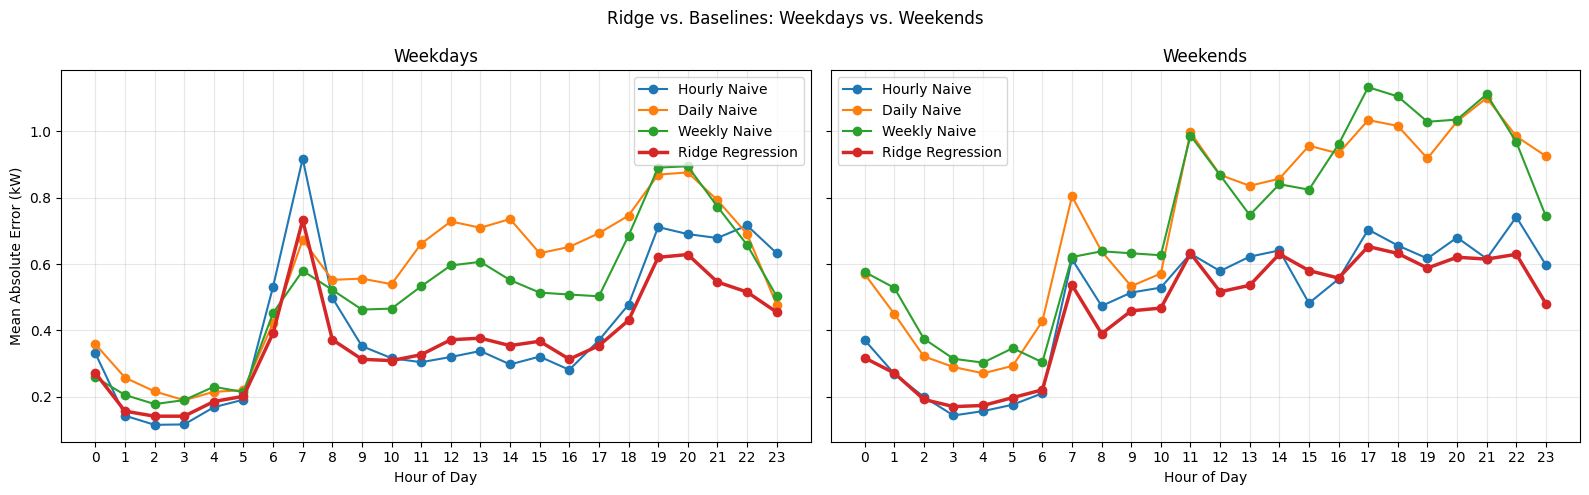

In [45]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, profile, title in [
    (axes[0], weekday_profile, "Weekdays"),
    (axes[1], weekend_profile, "Weekends")
]:
    ax.plot(
        profile.index,
        profile["hourly_error"],
        marker="o",
        label="Hourly Naive"
    )

    ax.plot(
        profile.index,
        profile["daily_error"],
        marker="o",
        label="Daily Naive"
    )

    ax.plot(
        profile.index,
        profile["weekly_error"],
        marker="o",
        label="Weekly Naive"
    )

    ax.plot(
        profile.index,
        profile["ridge_error"],
        marker="o",
        linewidth=2.5,
        label="Ridge Regression"
    )

    ax.set_title(title)
    ax.set_xlabel("Hour of Day")
    ax.set_xticks(range(24))
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Mean Absolute Error (kW)")

fig.suptitle(
    "Ridge vs. Baselines: Weekdays vs. Weekends"
)

plt.tight_layout()
plt.show()

In [47]:
error_by_day_type.loc[
    [(False, 7), (True, 7)],
    ["ridge_error", "hourly_error", "weekly_error"]
]

,,ridge_error,hourly_error,weekly_error
is_weekend,hour,,,
False,7,0.732490,0.917641,0.579702
True,7,0.536645,0.614627,0.621075
